<a href="https://colab.research.google.com/github/dhatrisrivadupu/ML-projects/blob/main/week1ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#import libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler, LabelEncoder
from sklearn.impute import SimpleImputer

In [ ]:
# Reading the file
df = pd.read_csv('/content/cs_students.csv')
print("Success")

Success


In [ ]:
df.shape

(180, 12)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180 entries, 0 to 179
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Student ID         180 non-null    int64  
 1   Name               180 non-null    object 
 2   Gender             180 non-null    object 
 3   Age                179 non-null    float64
 4   GPA                179 non-null    float64
 5   Major              180 non-null    object 
 6   Interested Domain  180 non-null    object 
 7   Projects           179 non-null    object 
 8   Future Career      178 non-null    object 
 9   Python             178 non-null    object 
 10  SQL                180 non-null    object 
 11  Java               178 non-null    object 
dtypes: float64(2), int64(1), object(9)
memory usage: 17.0+ KB


In [ ]:
df.describe()

,Student ID,Age,GPA
count,180.000000,179.000000,179.000000
mean,90.500000,22.111732,3.615084
std,52.105662,2.830180,0.177835
min,1.000000,20.000000,3.200000
25%,45.750000,21.000000,3.500000
50%,90.500000,22.000000,3.600000
75%,135.250000,22.000000,3.700000
max,180.000000,37.000000,3.900000


In [ ]:
# Null values count
df.isnull().sum()

,0
Student ID,0
Name,0
Gender,0
Age,1
GPA,1
Major,0
Interested Domain,0
Projects,1
Future Career,2
Python,2


In [ ]:
# Duplicate Records
print("no. of duplicate rows : ", df.duplicated().sum())

no. of duplicate rows :  0


In [ ]:
# imputation filling columns using meand, mode
df['Age'] = df['Age'].fillna(df['Age'].mean())
df['Projects'] = df['Projects'].fillna(df['Projects'].mode()[0])
df['Python'] = df['Python'].fillna(df['Python'].mode()[0])
df['Java'] = df['Java'].fillna(df['Java'].mode()[0])
df['GPA'] = df['GPA'].fillna(df['GPA'].mean())

In [ ]:
df['GPA'] = df['GPA'].fillna(df['GPA'].mean())

In [ ]:
df.isnull().sum()

,0
Student ID,0
Name,0
Gender,0
Age,0
GPA,0
Major,0
Interested Domain,0
Projects,0
Future Career,2
Python,0


In [ ]:
#Label Encoding
le = LabelEncoder()
df['Gender'] = le.fit_transform(df['Gender'])
print(df['Gender'].head())

0    1
1    0
2    1
3    0
4    1
Name: Gender, dtype: int64


In [ ]:
# One hot Encoding
df = pd.get_dummies(df, columns=['SQL'])
print(df.head())

   Student ID           Name  Gender   Age  GPA             Major  \
0           1     John Smith       1  21.0  3.5  Computer Science   
1           2  Alice Johnson       0  20.0  3.2  Computer Science   
2           3   Robert Davis       1  22.0  3.8  Computer Science   
3           4   Emily Wilson       0  21.0  3.7  Computer Science   
4           5  Michael Brown       1  23.0  3.4  Computer Science   

         Interested Domain             Projects                 Future Career  \
0  Artificial Intelligence  Chatbot Development   Machine Learning Researcher   
1             Data Science       Data Analytics                Data Scientist   
2     Software Development   E-commerce Website             Software Engineer   
3          Web Development   Full-Stack Web App                 Web Developer   
4            Cybersecurity     Network Security  Information Security Analyst   

    Python     Java  SQL_Average  SQL_Strong  SQL_Weak  
0   Strong     Weak        False        T

In [ ]:
# Normalization - MinMaxScaling
scaler = MinMaxScaler()
df[['Age', 'GPA']] = scaler.fit_transform(df[['Age', 'GPA']])
print(df[['Age', 'GPA']].head())

        Age       GPA
0  0.058824  0.428571
1  0.000000  0.000000
2  0.117647  0.857143
3  0.058824  0.714286
4  0.176471  0.285714


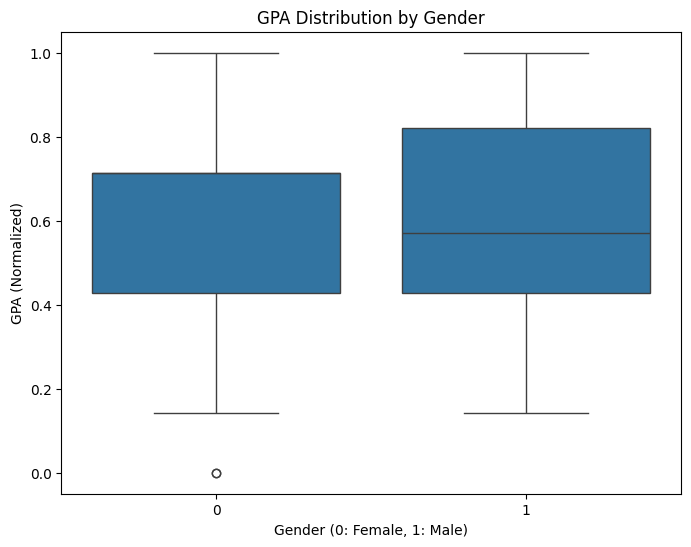

In [ ]:
# Visualization
plt.figure(figsize=(8, 6))
sns.boxplot(x='Gender', y='GPA', data=df)
plt.title('GPA Distribution by Gender')
plt.xlabel('Gender (0: Female, 1: Male)')
plt.ylabel('GPA (Normalized)')
plt.show()

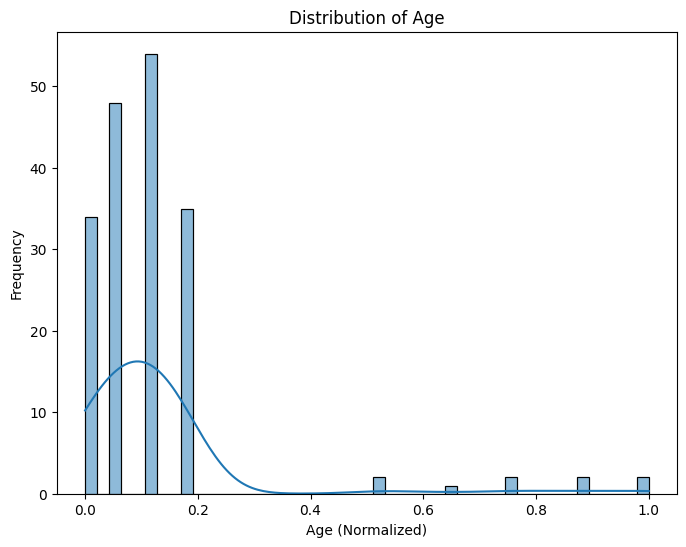

In [ ]:
plt.figure(figsize=(8, 6))
sns.histplot(df['Age'], kde=True)
plt.title('Distribution of Age')
plt.xlabel('Age (Normalized)')
plt.ylabel('Frequency')
plt.show()

In [ ]:
# Outliers Detection
Q1 = df['Age'].quantile(0.25)
Q3 = df['Age'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
outliers = df[(df['Age'] < lower_bound) | (df['Age'] > upper_bound)]
print(outliers)

    Student ID                 Name  Gender       Age       GPA  \
76          77        Agent Coulson       1  0.882353  1.000000   
77          78           Agent Hill       0  0.764706  0.857143   
78          79    Agent Melinda May       0  1.000000  0.714286   
79          80  Agent Daisy Johnson       0  0.529412  0.571429   
80          81        Agent Simmons       0  0.647059  0.428571   
81          82           Agent Fitz       1  0.882353  1.000000   
82          83           Agent Mack       1  1.000000  0.857143   
83          84    Agent Bobbi Morse       0  0.529412  0.714286   
84          85   Agent Lance Hunter       1  0.764706  0.571429   

               Major        Interested Domain                     Projects  \
76  Computer Science          Cloud Computing               AWS Deployment   
77  Computer Science            Cybersecurity             Network Security   
78  Computer Science      Database Management       SQL Query Optimization   
79  Computer Scie

In [ ]:
print("After removing outliers, DataSet shape: ", df.shape)

After removing outliers, DataSet shape:  (180, 14)


In [ ]:
print("After preprocessing")
display(df.head())

After preprocessing


,Student ID,Name,Gender,Age,GPA,Major,Interested Domain,Projects,Future Career,Python,Java,SQL_Average,SQL_Strong,SQL_Weak
0,1,John Smith,1,0.058824,0.428571,Computer Science,Artificial Intelligence,Chatbot Development,Machine Learning Researcher,Strong,Weak,False,True,False
1,2,Alice Johnson,0,0.000000,0.000000,Computer Science,Data Science,Data Analytics,Data Scientist,Average,Weak,False,True,False
2,3,Robert Davis,1,0.117647,0.857143,Computer Science,Software Development,E-commerce Website,Software Engineer,Strong,Average,False,True,False
3,4,Emily Wilson,0,0.058824,0.714286,Computer Science,Web Development,Full-Stack Web App,Web Developer,Weak,Strong,False,True,False
4,5,Michael Brown,1,0.176471,0.285714,Computer Science,Cybersecurity,Network Security,Information Security Analyst,Average,Strong,False,False,True
